# Feature selection

Each step looks at the data first, then decides what to drop or change.

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import QuantileTransformer

from aml.data import load_data
from aml.data import load_features
from aml.features import aligned_copies
from aml.features import beats_shadows
from aml.features import constant_features
from aml.features import copy_groups
from aml.features import copy_noise
from aml.features import correlated_block
from aml.features import duplicate_features
from aml.features import merge_copies
from aml.features import outlier_scores
from aml.features import robust_scale
from aml.features import spread_stats


X_train, y_train, X_test = load_data()
print(X_train.shape, y_train.shape, X_test.shape)

(1212, 832) (1212,) (776, 832)


## Step 1: constant features and exact copies

Constant: a single non-null value. Exact copy: |correlation| = 1 with an earlier feature (possibly rescaled); the first of each pair is kept.

In [19]:
constant = constant_features(X_train)
duplicates = duplicate_features(X_train.drop(columns=constant))
print(f"Constant ({len(constant)}): {constant}")
print(f"Exact copies ({len(duplicates)}): {duplicates}")
X_step1 = X_train.drop(columns=constant + duplicates)
X_step1.shape

Constant (4): ['x104', 'x129', 'x489', 'x530']
Exact copies (1): ['x774']


(1212, 827)

## Step 2: missing values and feature scales

Scale of a feature: its IQR (the middle 50% of values), so a few extreme values don't set it.

In [20]:
missing = X_step1.isna().mean()
missing_test = X_test[X_step1.columns].isna().mean()
print(
    f"Missing in train: {missing.mean():.1%} overall, per feature {missing.min():.1%} to {missing.max():.1%}"
)
print(f"Missing in test:  {missing_test.mean():.1%} overall")
print(
    f"Missing per row (train): {X_step1.isna().mean(axis=1).describe()[['min', '50%', 'max']].round(3).to_dict()}"
)

Missing in train: 7.6% overall, per feature 5.4% to 10.0%
Missing in test:  6.3% overall
Missing per row (train): {'min': 0.045, '50%': 0.076, 'max': 0.108}


IQR ranges from 0.0462 to 2.79e+22


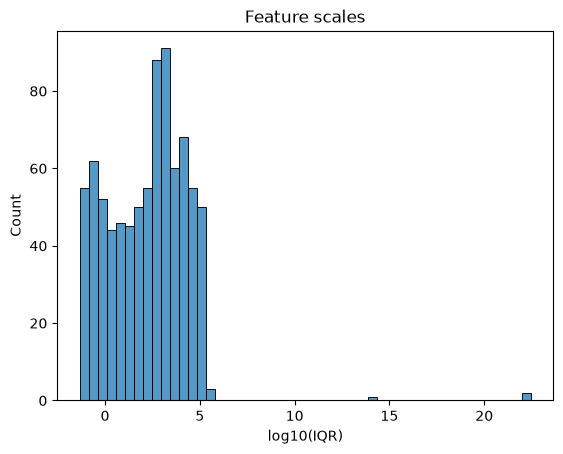

,median,iqr,min,max
x336,3.665737e+04,4.619451e-02,3.665732e+04,3.665742e+04
x628,4.245200e+04,4.732813e-02,4.245195e+04,4.245205e+04
x519,6.734150e+05,4.734865e-02,6.734150e+05,6.734151e+05
x179,8.644360e+05,4.826719e-02,8.644360e+05,8.644361e+05
x307,3.726631e+05,4.837413e-02,3.726631e+05,3.726632e+05
x554,1.477973e+06,2.541155e+05,6.480858e+05,2.356201e+06
x342,2.747859e+06,3.963505e+05,1.168237e+06,5.032106e+06
x596,-1.556121e+14,1.364833e+14,-8.756492e+14,2.926746e+14
x173,-1.373094e+22,2.499513e+22,-2.937933e+23,7.002915e+22
x665,3.737021e+22,2.790652e+22,-6.392632e+22,9.935455e+23


In [21]:
iqr = X_step1.quantile(0.75) - X_step1.quantile(0.25)
scales = pd.DataFrame(
    {"median": X_step1.median(), "iqr": iqr, "min": X_step1.min(), "max": X_step1.max()}
).sort_values("iqr")
print(f"IQR ranges from {iqr[iqr > 0].min():.3g} to {iqr.max():.3g}")

sns.histplot(np.log10(iqr[iqr > 0]), bins=50)
plt.xlabel("log10(IQR)")
plt.title("Feature scales")
plt.show()
pd.concat([scales.head(5), scales.tail(5)])

## Step 3: spread

Std of the non-null values, sorted highest to lowest, with the number of distinct values and the share of the most common value. Raw std depends on each feature's units (step 2), so this is for looking only.

In [22]:
spread = spread_stats(X_step1)
spread

,std,nunique,top_share,missing
x665,4.061152e+22,1132,0.000883,0.066007
x173,2.570333e+22,1131,0.000884,0.066832
x596,1.280957e+14,1109,0.000902,0.084983
x342,3.640997e+05,1099,0.000910,0.093234
x132,2.160821e+05,1110,0.000901,0.084158
...,...,...,...,...
x628,2.847403e-02,1135,0.000881,0.063531
x529,2.844934e-02,1114,0.000898,0.080858
x492,2.837369e-02,1118,0.000894,0.077558
x519,2.824004e-02,1113,0.000898,0.081683


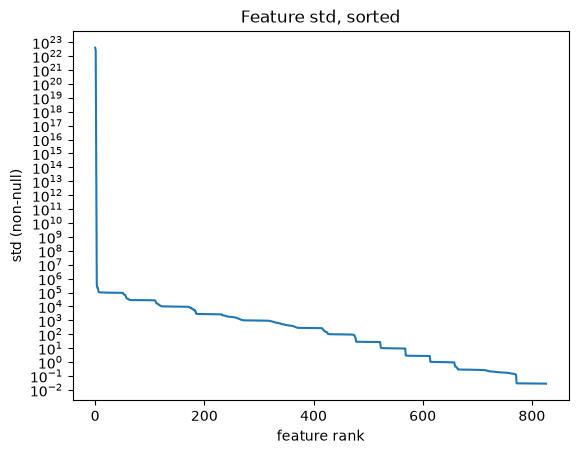

In [23]:
plt.plot(spread["std"].to_numpy())
plt.yscale("symlog", linthresh=1e-2)
plt.xlabel("feature rank")
plt.ylabel("std (non-null)")
plt.title("Feature std, sorted")
plt.show()

In [24]:
spread.sort_values("top_share", ascending=False).head(10)

,std,nunique,top_share,missing
x143,12.850896,444,0.595803,0.095710
x413,108.723639,1116,0.003575,0.076733
x363,0.029108,1107,0.001805,0.085809
x67,0.029054,1111,0.001799,0.082508
x605,0.029844,1112,0.001797,0.081683
x208,0.028944,1121,0.001783,0.074257
x450,0.028779,1138,0.001756,0.060231
x79,12123.578015,1091,0.000917,0.099835
x381,2731.345579,1093,0.000915,0.098185
x313,2.816667,1094,0.000914,0.097360


The std plot has a flat step at about 0.029 = 0.1/√12: the std of a uniform distribution of width 0.1. These features are a constant plus uniform noise on an interval of exactly 0.1. Their kurtosis is −1.2, as for a uniform distribution, and they don't correlate with any other feature or with `y`: pure noise. They are dropped.

In [25]:
value_range = X_step1.max() - X_step1.min()
uniform_noise = value_range.index[value_range.between(0.09, 0.11)].tolist()
print(
    f"Dropping {len(uniform_noise)} features with a value range of 0.1: {uniform_noise}"
)
pd.DataFrame(
    {
        "range": value_range[uniform_noise],
        "std": X_step1[uniform_noise].std(),
        "kurtosis": X_step1[uniform_noise].kurt(),
        "corr_with_y": X_step1[uniform_noise].corrwith(y_train, method="spearman"),
    }
).describe().round(3)

Dropping 55 features with a value range of 0.1: ['x33', 'x67', 'x68', 'x147', 'x166', 'x179', 'x183', 'x185', 'x189', 'x195', 'x196', 'x207', 'x208', 'x229', 'x262', 'x271', 'x281', 'x289', 'x292', 'x295', 'x296', 'x305', 'x307', 'x336', 'x338', 'x363', 'x384', 'x385', 'x446', 'x450', 'x462', 'x466', 'x492', 'x500', 'x519', 'x529', 'x550', 'x556', 'x580', 'x583', 'x586', 'x593', 'x605', 'x620', 'x625', 'x628', 'x666', 'x679', 'x682', 'x709', 'x724', 'x755', 'x803', 'x808', 'x815']


,range,std,kurtosis,corr_with_y
count,55.0,55.000,55.000,55.000
mean,0.1,0.029,-1.206,-0.011
std,0.0,0.000,0.034,0.031
min,0.1,0.028,-1.292,-0.089
25%,0.1,0.029,-1.226,-0.034
50%,0.1,0.029,-1.206,-0.021
75%,0.1,0.029,-1.189,0.011
max,0.1,0.030,-1.131,0.053


In [26]:
X_step3 = X_step1.drop(columns=uniform_noise)
X_step3.shape

(1212, 772)

## Step 4: outlier values within a feature

Steps 4–6 don't use `y`, so they run on train + test together. Robust scale: (x − median) / IQR. Count values beyond a few cutoffs, then look at the features with the most extreme values.

In [27]:
X_all = pd.concat([X_step3, X_test[X_step3.columns]], ignore_index=True)
z = robust_scale(X_all).abs()
print({cutoff: int((z > cutoff).sum().sum()) for cutoff in (3, 5, 10, 20)})
extreme = z.max().sort_values(ascending=False).head(8).index
X_all[extreme].describe(percentiles=[0.01, 0.5, 0.99]).T

{3: 2379, 5: 464, 10: 229, 20: 8}


,count,mean,std,min,1%,50%,99%,max
x665,1852.0,4.380992e+22,3.535936e+22,-6.392632e+22,-6.193365e+21,3.761830e+22,1.426662e+23,9.935455e+23
x143,1826.0,5.436739e+00,1.197415e+01,-5.425086e+00,0.000000e+00,0.000000e+00,5.727087e+01,1.795433e+02
x413,1844.0,1.044968e+02,9.332570e+01,0.000000e+00,1.358789e+01,9.375088e+01,2.806779e+02,1.616822e+03
x742,1846.0,6.389966e+04,3.663214e+04,1.911385e+04,3.883975e+04,5.206754e+04,1.925365e+05,2.232861e+05
x641,1823.0,8.330227e+01,1.064722e+02,-1.072077e+02,-9.838119e+00,5.295201e+01,5.281374e+02,1.405798e+03
x115,1844.0,5.114710e+03,6.354309e+03,-1.219271e+04,-2.988895e+03,2.958206e+03,3.074116e+04,5.218473e+04
x173,1849.0,-1.851461e+22,2.429282e+22,-2.937933e+23,-9.359092e+22,-1.373094e+22,3.041232e+22,7.002915e+22
x796,1853.0,1.046523e+02,5.515978e+01,0.000000e+00,1.097350e+01,9.701009e+01,2.846360e+02,7.740325e+02


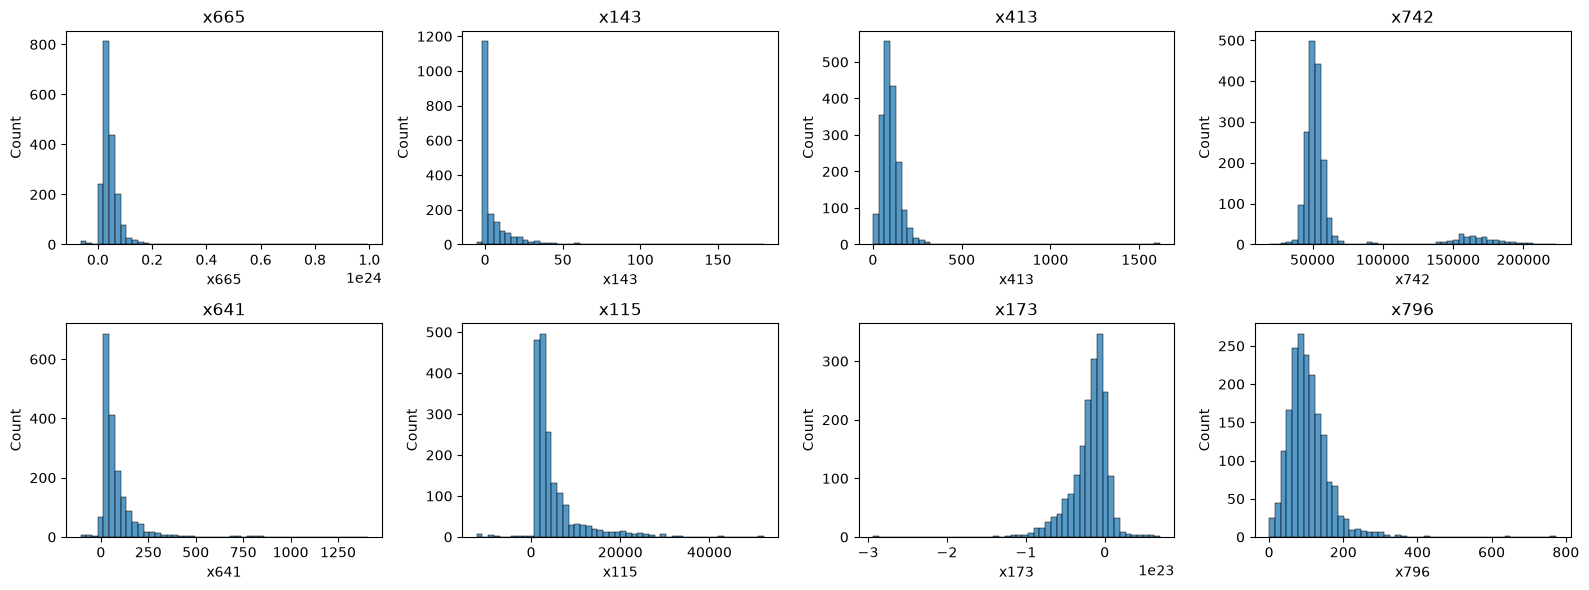

In [28]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.flat, extreme, strict=True):
    sns.histplot(X_all[col], bins=50, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

The extreme values sit in about 10 features with long tails or a second cluster (x742), and several of them (x115, x641, x507, x415) are among the most important features. They look like real values, not planted ones, so nothing is removed here: the quantile transform handles the tails.

## Step 5: groups of noisy copies

Features linked by |Spearman| ≥ threshold, transitively (a~b and b~c puts a, b, c in one group). `min_corr` is the weakest link inside the largest group: once it drops far below the threshold, different groups are being chained together, not copies.

In [29]:
spearman = X_all.corr(method="spearman").abs()
rows = []
for t in np.arange(0.99, 0.695, -0.01).round(2):
    gs = copy_groups(spearman, t)
    largest = max(gs, key=len)
    rows.append(
        {
            "threshold": t,
            "groups": len(gs),
            "removed": sum(map(len, gs)) - len(gs),
            "largest": len(largest),
            "min_corr": spearman.loc[largest, largest].min().min(),
            "sizes": sorted(map(len, gs), reverse=True),
        }
    )
pd.DataFrame(rows)

,threshold,groups,removed,largest,min_corr,sizes
0,0.99,4,32,18,0.936865,"[18, 11, 5, 2]"
1,0.98,4,35,21,0.915077,"[21, 11, 5, 2]"
2,0.97,4,40,24,0.896739,"[24, 12, 6, 2]"
3,0.96,6,43,24,0.896739,"[24, 12, 6, 3, 2, 2]"
4,0.95,6,45,24,0.896739,"[24, 14, 6, 3, 2, 2]"
5,0.94,7,46,24,0.896739,"[24, 14, 6, 3, 2, 2, 2]"
6,0.93,5,49,45,0.695123,"[45, 3, 2, 2, 2]"
7,0.92,6,50,45,0.695123,"[45, 3, 2, 2, 2, 2]"
8,0.91,6,50,45,0.695123,"[45, 3, 2, 2, 2, 2]"
9,0.90,8,53,46,0.695123,"[46, 3, 2, 2, 2, 2, 2, 2]"


In [30]:
COPY_THRESHOLD = 0.94  # lowest threshold before groups start chaining together
groups = copy_groups(spearman, COPY_THRESHOLD)
pd.DataFrame(
    {
        "size": [len(g) for g in groups],
        "min_corr": [spearman.loc[g, g].min().min() for g in groups],
        "members": groups,
    }
)

,size,min_corr,members
0,24,0.896739,"[x0, x79, x123, x148, x174, x202, x240, x250, ..."
1,6,0.964929,"[x15, x132, x610, x665, x668, x780]"
2,14,0.873386,"[x40, x69, x151, x230, x231, x278, x288, x342,..."
3,3,0.884984,"[x133, x334, x465]"
4,2,0.945778,"[x159, x702]"
5,2,0.952048,"[x425, x590]"
6,2,0.986601,"[x493, x596]"


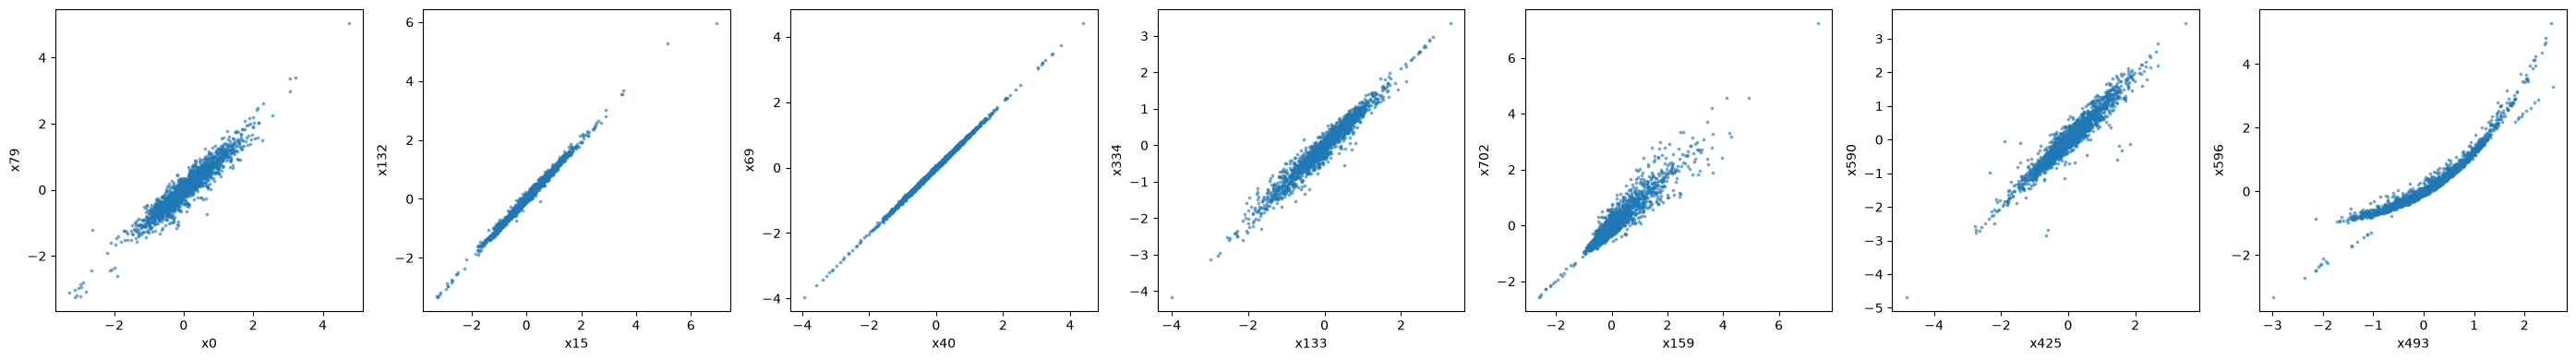

In [31]:
fig, axes = plt.subplots(1, len(groups), figsize=(4 * len(groups), 4))
for ax, g in zip(axes, groups, strict=True):
    W = aligned_copies(X_all, g)
    ax.scatter(W.iloc[:, 0], W.iloc[:, 1], s=3, alpha=0.5)
    ax.set_xlabel(g[0])
    ax.set_ylabel(g[1])
plt.tight_layout()
plt.show()

## Step 6: merge each group

`noise` is each member's robust spread around the group's row-wise median. Every group has a member with noise close to 0: probably the original feature, the rest being noisy copies of it. So each group becomes its least noisy member, with missing values filled from the next least noisy member that has one.

In [32]:
X_merged = merge_copies(X_all, groups)
X_train_merged = X_merged.iloc[: len(X_step3)].set_index(X_step3.index)
X_test_merged = X_merged.iloc[len(X_step3) :].set_index(X_test.index)
print(f"{X_step3.shape[1]} -> {X_train_merged.shape[1]} features")

for g in groups:
    noise = copy_noise(X_all, g)
    missing_before = X_all[noise.index[0]].isna().mean()
    missing_after = X_merged[noise.index[0]].isna().mean()
    print(
        f"\n{noise.index[0]} group ({len(g)}): "
        f"missing {missing_before:.1%} -> {missing_after:.1%}"
    )
    print(noise.round(3).to_dict())

772 -> 726 features

x348 group (24): missing 7.1% -> 0.0%
{'x348': 0.01, 'x790': 0.016, 'x579': 0.018, 'x727': 0.024, 'x392': 0.029, 'x442': 0.03, 'x634': 0.038, 'x317': 0.039, 'x240': 0.047, 'x79': 0.05, 'x316': 0.061, 'x715': 0.063, 'x202': 0.08, 'x568': 0.082, 'x614': 0.083, 'x148': 0.091, 'x505': 0.105, 'x333': 0.106, 'x250': 0.109, 'x123': 0.141, 'x502': 0.144, 'x698': 0.197, 'x174': 0.197, 'x0': 0.229}

x668 group (6): missing 7.3% -> 0.0%
{'x668': 0.015, 'x132': 0.035, 'x610': 0.038, 'x15': 0.041, 'x665': 0.077, 'x780': 0.15}

x40 group (14): missing 6.6% -> 0.0%
{'x40': 0.013, 'x278': 0.017, 'x374': 0.017, 'x69': 0.024, 'x562': 0.033, 'x675': 0.041, 'x230': 0.056, 'x288': 0.058, 'x151': 0.061, 'x479': 0.09, 'x231': 0.109, 'x414': 0.135, 'x342': 0.263, 'x819': 0.301}

x334 group (3): missing 6.4% -> 0.1%
{'x334': 0.0, 'x133': 0.136, 'x465': 0.14}

x702 group (2): missing 7.0% -> 0.7%
{'x702': 0.089, 'x159': 0.09}

x425 group (2): missing 6.1% -> 0.6%
{'x425': 0.085, 'x590': 0.0

## Step 7: outlier rows

Rows flagged on the merged data, compared with the flags on the unmerged data. A second check that doesn't use `y`: each row's distance to its nearest neighbour (quantile transformed, median imputed). The flagged rows sit in one tight cluster, and no test row is in it.

55 outliers, 53 also flagged before merging


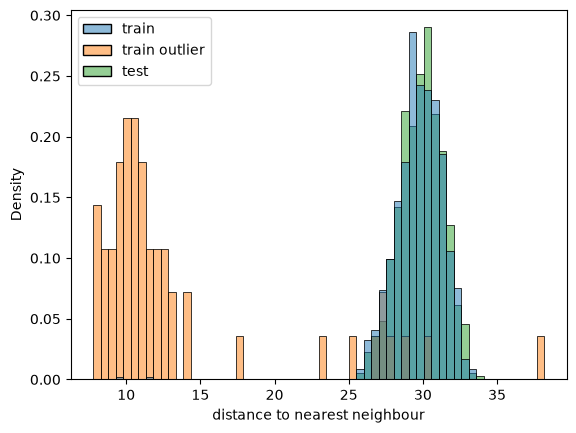

In [33]:
OUTLIER_FRAC = 0.045
n_out = round(OUTLIER_FRAC * len(X_train_merged))
outliers = outlier_scores(X_train_merged, y_train).index[:n_out]
outliers_before = outlier_scores(X_step3, y_train).index[:n_out]
print(
    f"{n_out} outliers, {len(outliers.intersection(outliers_before))} also flagged before merging"
)

Z_q = make_pipeline(
    QuantileTransformer(output_distribution="normal", random_state=25),
    SimpleImputer(strategy="median"),
).fit_transform(X_merged)
dist = NearestNeighbors(n_neighbors=2).fit(Z_q).kneighbors(Z_q)[0][:, 1]
group = np.where(X_train_merged.index.isin(outliers), "train outlier", "train")
group = np.concatenate([group, np.full(len(X_test_merged), "test")])
sns.histplot(x=dist, hue=group, bins=60, stat="density", common_norm=False)
plt.xlabel("distance to nearest neighbour")
plt.show()

## Step 8: RF and MI importance, and the union set

Computed by `scripts/feature_importance.py` (HPC) on the cleaned features without the outlier rows. `shadow_*` rows are shuffled copies of real features: a feature is selected if it beats the best shadow. The union set (RF selected + MI selected + the correlated block) was ranked by the selection-curve run (step 9).

In [34]:
importance = {
    name: pd.read_csv(f"../outputs/importance_{name}.csv", index_col=0)
    for name in ("rf", "mi")
}
selected = {name: beats_shadows(imp) for name, imp in importance.items()}
block = set(correlated_block(X_merged))
union = selected["rf"] | selected["mi"] | block
print({name: len(s) for name, s in selected.items()}, f"block {len(block)}")
print(f"Union set: {len(union)} features")

Threshold 0.00006: keeping 231 features


,mean,std
x115,0.031626,0.003226
x415,0.018735,0.000902
x458,0.018637,0.001451
x507,0.015582,0.001735
x159,0.015193,0.001313
x641,0.014051,0.002233
x702,0.012750,0.001704
x334,0.008871,0.002025
x485,0.008551,0.001048
x465,0.008310,0.001182


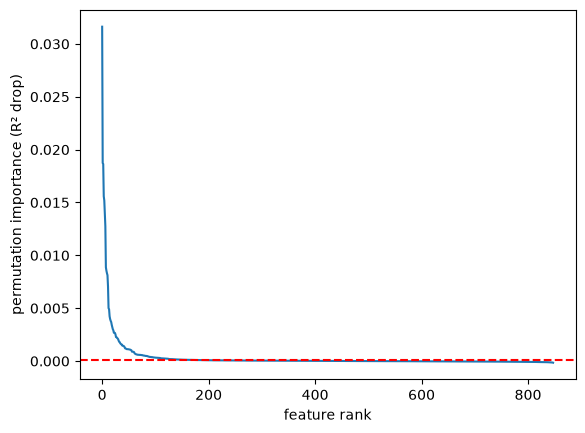

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, imp) in zip(axes, importance.items(), strict=True):
    is_shadow = imp.index.str.startswith("shadow_")
    ax.plot(imp["mean"].to_numpy())
    ax.axhline(imp.loc[is_shadow, "mean"].max(), color="red", linestyle="--")
    ax.set_xlabel("feature rank")
    ax.set_title(name)
plt.show()

## Step 9: how many features

Selection-curve run (HPC, script removed after the decision; in git history): GP R² for the top k features of each ranking over 5 folds x 3 repeats. No top-k set beat the full correlated block (0.711), so the block is the locked feature set.

In [ ]:
curves = pd.read_csv("../outputs/selection_curves.csv")
summary = curves.groupby(["ranking", "k"])["r2"].agg(["mean", "std"]).reset_index()
for name, s in summary.groupby("ranking"):
    plt.plot(s["k"], s["mean"], marker="o", label=name)
plt.xlabel("number of features k")
plt.ylabel("R² (mean over 15 folds)")
plt.legend()
plt.show()
summary.pivot(index="k", columns="ranking", values="mean").round(4)

## Step 10: dimension reduction (PCA / PLS)

The 185 block features are noisy, correlated measurements of fewer underlying factors. A GP with one shared length scale weighs all 185 dimensions equally, so fewer, cleaner inputs could help it. Uses the locked features (`scripts/preprocess.py`).

- **PCA** (no `y`): directions of largest variance. A component counts as real if it explains more variance than the same component of the data with every column shuffled independently (parallel analysis: shuffling keeps each feature's distribution but destroys all correlations).
- **PLS** (uses `y`): directions most related to age.

The linear CV curves below only narrow down the range of components; a GP sweep on the HPC decides.

In [ ]:
X_loc, y_loc, X_test_loc, inlier_loc = load_features()
Z_all = pd.concat([X_loc, X_test_loc], ignore_index=True)  # PCA uses no y

real = PCA().fit(Z_all).explained_variance_ratio_
rng = np.random.default_rng(25)
noise = (
    PCA()
    .fit(Z_all.apply(lambda c: rng.permutation(c.to_numpy())))
    .explained_variance_ratio_
)
n_real = int(np.argmax(real < noise))  # first component below the shuffled level
cumulative = real.cumsum()
print(f"{n_real} components explain more than shuffled data")
print(
    {
        f"{p:.0%} variance": int(np.searchsorted(cumulative, p)) + 1
        for p in (0.5, 0.8, 0.9, 0.95)
    }
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
k = np.arange(1, 61)
axes[0].plot(k, real[:60], marker="o", ms=3, label="block features")
axes[0].plot(k, noise[:60], color="grey", ls="--", label="every column shuffled")
axes[0].axvline(n_real, color="red", ls=":", label=f"{n_real} components")
axes[0].set(
    yscale="log",
    xlabel="component",
    ylabel="share of variance",
    title="PCA: variance per component",
)
axes[0].legend()
axes[1].plot(np.arange(1, len(cumulative) + 1), cumulative)
axes[1].axvline(n_real, color="red", ls=":")
axes[1].set(
    xlabel="number of components",
    ylabel="cumulative share of variance",
    title="PCA: cumulative",
)
plt.tight_layout()
plt.show()

In [ ]:
X_in, y_in = X_loc[inlier_loc], y_loc[inlier_loc]
cv = KFold(5, shuffle=True, random_state=25)
ks = [1, 2, 3, 5, 8, 10, 15, 20, 30, 40, 60, 80, 120, 185]
linear_r2 = {
    "PCA + linear regression": [
        cross_val_score(
            make_pipeline(PCA(k), LinearRegression()), X_in, y_in, cv=cv
        ).mean()
        for k in ks
    ],
    "PLS": [
        cross_val_score(PLSRegression(k, scale=False), X_in, y_in, cv=cv).mean()
        for k in ks
    ],
}
for name, r2 in linear_r2.items():
    plt.plot(ks, r2, marker="o", label=name)
plt.axhline(0.716, color="black", ls="--", label="GP on all 185 features")
plt.axvline(n_real, color="red", ls=":", label=f"{n_real} PCA components above noise")
plt.xscale("log")
plt.ylim(0.4, 0.75)
plt.xlabel("number of components")
plt.ylabel("R² (5-fold CV, inlier rows)")
plt.legend()
plt.show()
pd.DataFrame(linear_r2, index=ks).round(4)